# TOAST Maploader

Author : Henry Nachman

---

A file to load filterbin maps after they have been made by TOAST

# Imports

In [15]:
import matplotlib.pyplot as plt
import os, sys
from photutils.centroids import centroid_com, centroid_2dg, centroid_quadratic

abspath = os.path.dirname(os.path.abspath("toast_maploader.ipynb"))
fig_out_path = "/shared_home/henachman/home/SO_PointingReqs/output_analysis"
if abspath not in sys.path:
    sys.path.append(abspath)

from toast_fbmaploader import *

In [2]:
path_to_data = "/shared_home/henachman/data/sim_outputs/Mars/"
SSO = "Mars"
if SSO=="Mars":
    ra = 111.0992
    dec = 25.1832
if SSO=="Jupiter":
    ra = 72.4123427736188
    dec = 22.100098621604207
else:
    ra = 111.0992
    dec = 25.1832
rot = [ra, dec]

maps_dict = {}

In [3]:
def centroid_center(map, rot_guess, max_pix=False):
    gnommap = hp.gnomview(map, 
                rot=rot_guess,
                xsize=1000,
                reso=0.1,
                return_projected_map=True,
                # no_plot=True,
    )
                # no_plot=True)
    flat_idx = np.argmax(gnommap)
    row, col = divmod(flat_idx, gnommap.shape[1])
    x_size, y_size = np.shape(gnommap)

    def pix_to_coord(pix, reso=0.1, x_size=1000):
        return (pix - x_size//2)*reso/60
    
    if max_pix:
        rot_est = -pix_to_coord(np.array([row, col]))+np.array(rot_guess)


    box_size = 50
    x_cent, y_cent = centroid_2dg(gnommap[int(row)-box_size:int(row)+box_size, int(col)-box_size:int(col)+box_size])
    cent_pix = np.array([col + x_cent, row + y_cent]) # print(f"Centroid at: x = {col + x_cent}, y = {row + y_cent}")
    rot_est = pix_to_coord(cent_pix)+np.array(rot_guess)
    return rot_est


In [6]:
run_path = {
    "plain" : "Mars_PS_2arcmin_f090_261019_204815",
    "offset" : "Mars_PS_offset_2arcmin_f090_261019_204824",
    "jitter" : "Mars_PS_jitter_2arcmin_f090_261019_204832"
    }

for name, path in run_path.items():
    if name not in maps_dict:
        print(f"Adding {name}, {path}")
        hpmap = load_map(path, path_to_data=path_to_data)#, hits=True)
        rot_est = rot # centroid_center(hpmap, rot, True)
        maps_dict[name] = {"map": hpmap,
                           "rot_est": rot_est,
                           "path":path}

[111.18275818  25.26312775] [111.0992, 25.1832]


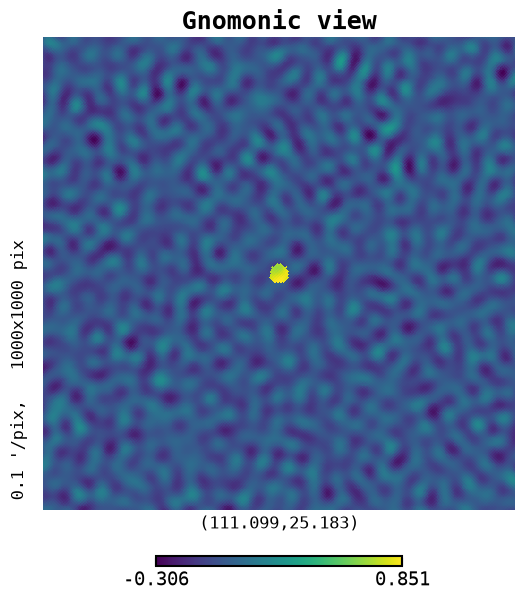

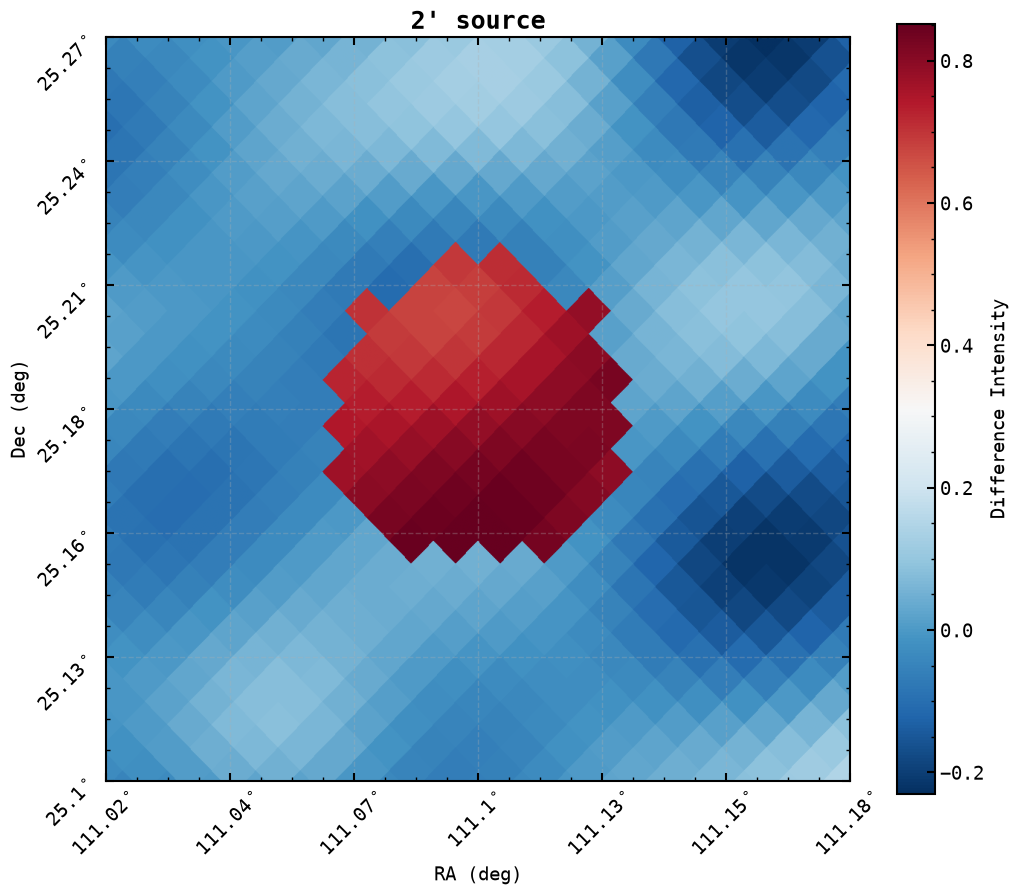

In [7]:
map_name = "plain"
maps_dict[map_name]["rot_est"] = centroid_center(maps_dict[map_name]["map"], rot, True)
print(maps_dict[map_name]["rot_est"], rot)
single_plot(maps_dict[map_name]["map"],
          rot=rot,
          xsize=1000,
          reso=0.01,
          show=False)
# print(centroid_center(maps_dict[map_name]["map"], rot))
plt.title("2' source")
plt.savefig(os.path.join(path_to_data, maps_dict[map_name]["path"], "filterbin_map.png"), dpi=300)

In [17]:

def diff_plot(map1, map2, rot, xsize=1000, reso=0.05, cmap='RdBu_r', deg=True, show=True, **kwargs):
    map1_gnom = hp.gnomview(map1, 
        rot=rot, 
        xsize=xsize,
        reso=reso,
        coord=["G"],
        cmap=cmap,
        return_projected_map=True,
        no_plot=True
    )
    map2_gnom = hp.gnomview(map2, 
        rot=rot, 
        xsize=xsize,
        reso=reso,
        coord=["G"],
        cmap=cmap,
        return_projected_map=True,
        no_plot=True
        )

    x_size, y_size = np.shape(map1_gnom)
    x_ticks = np.linspace(0, x_size, 7)
    y_ticks = np.linspace(0, y_size, 7)
    def pix_to_coord(pix, reso, x_size, deg):
        if deg:
            return (pix - x_size//2)*reso/60
        else:
            return (pix - x_size//2)*reso

    if deg:
        x_labels = np.round(rot[0]+pix_to_coord(x_ticks, reso, x_size, deg), 2)
        y_labels = np.round(rot[1]+pix_to_coord(y_ticks, reso, y_size, deg), 2) 
        x_labels_str = [str(i) + r"$^\circ$" for i in x_labels]
        y_labels_str = [str(i) + r"$^\circ$" for i in y_labels]
    else:
        x_labels = np.round(pix_to_coord(x_ticks, reso, x_size, deg), 2)
        y_labels = np.round(pix_to_coord(y_ticks, reso, y_size, deg), 2) 
        x_labels_str = [str(i) + "'" for i in x_labels]
        y_labels_str = [str(i) + "'" for i in y_labels]

    map1_gnom[map1_gnom == hp.UNSEEN] = np.nan
    map2_gnom[map2_gnom == hp.UNSEEN] = np.nan

    # 5. Subtract the two 2D maps
    subtracted_grid = map1_gnom - map2_gnom

    # 6. Plot the final result using standard matplotlib
    fig = plt.figure(figsize=(8,20))
    subfigs = fig.subfigures(3,1)
    # Truth
    subfig_top = subfigs[0]
    ax_top = subfig_top.subplots()
    im_top = ax_top.imshow(map1_gnom, origin='lower', cmap=cmap, **kwargs)
    subfig_top.colorbar(im_top, ax=ax_top, label='Difference Intensity')
    ax_top.set_title("Map 1")
    def set_axes(ax):
        ax.set_xticks(x_ticks, labels=x_labels_str, rotation=45)
        ax.set_yticks(y_ticks, labels=y_labels_str, rotation=45)
        if deg:
            ax.set_xlabel("RA (deg)")
            ax.set_ylabel("Dec (deg)")
        else:
            ax.set_xlabel(r"$\delta_{RA}$ (arcmin)")
            ax.set_ylabel(r"$\delta_{Ddec}$ (arcmin)")
    set_axes(ax_top)

    # Output Map
    subfig_mid = subfigs[1]
    ax_mid = subfig_mid.subplots()
    im_mid = ax_mid.imshow(map2_gnom, origin='lower', cmap=cmap, **kwargs)
    subfig_mid.colorbar(im_mid, ax=ax_mid, label='Difference Intensity')
    ax_mid.set_title("Map 2")
    set_axes(ax_mid)
    # Difference
    subfig_bottom = subfigs[2]
    ax_bottom = subfig_bottom.subplots()
    im_bottom = ax_bottom.imshow(subtracted_grid, origin='lower', cmap=cmap, **kwargs)
    subfig_bottom.colorbar(im_bottom, ax=ax_bottom, label='Difference Intensity')
    ax_bottom.set_title("Difference Map\nMap 1 - Map 2")
    set_axes(ax_bottom)
    if show:
        plt.show()
    axs = [ax_top, ax_mid, ax_bottom]
    return fig, axs


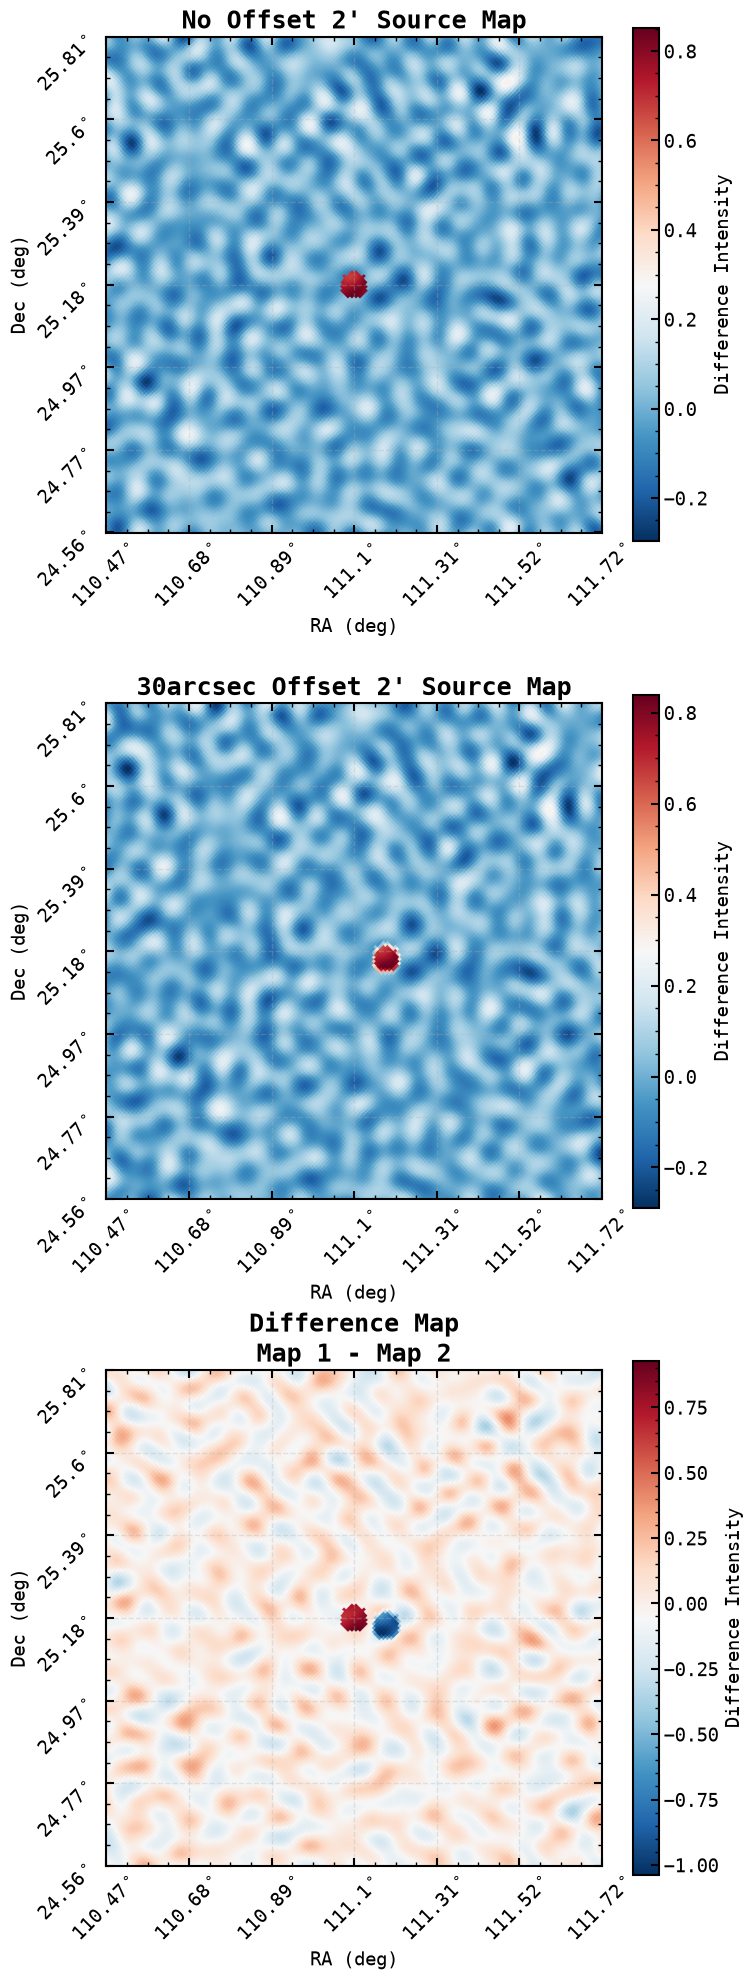

In [19]:
fig, axs = diff_plot(maps_dict["plain"]["map"],
          maps_dict["offset"]["map"],
          rot=rot,
          xsize=750,
          reso=0.1,
          deg=True,
          show=False)

axs[0].set_title("No Offset 2' Source Map")
axs[1].set_title("30arcsec Offset 2' Source Map")
plt.savefig(os.path.join(fig_out_path, "2arcmin_offset_diff.png"))

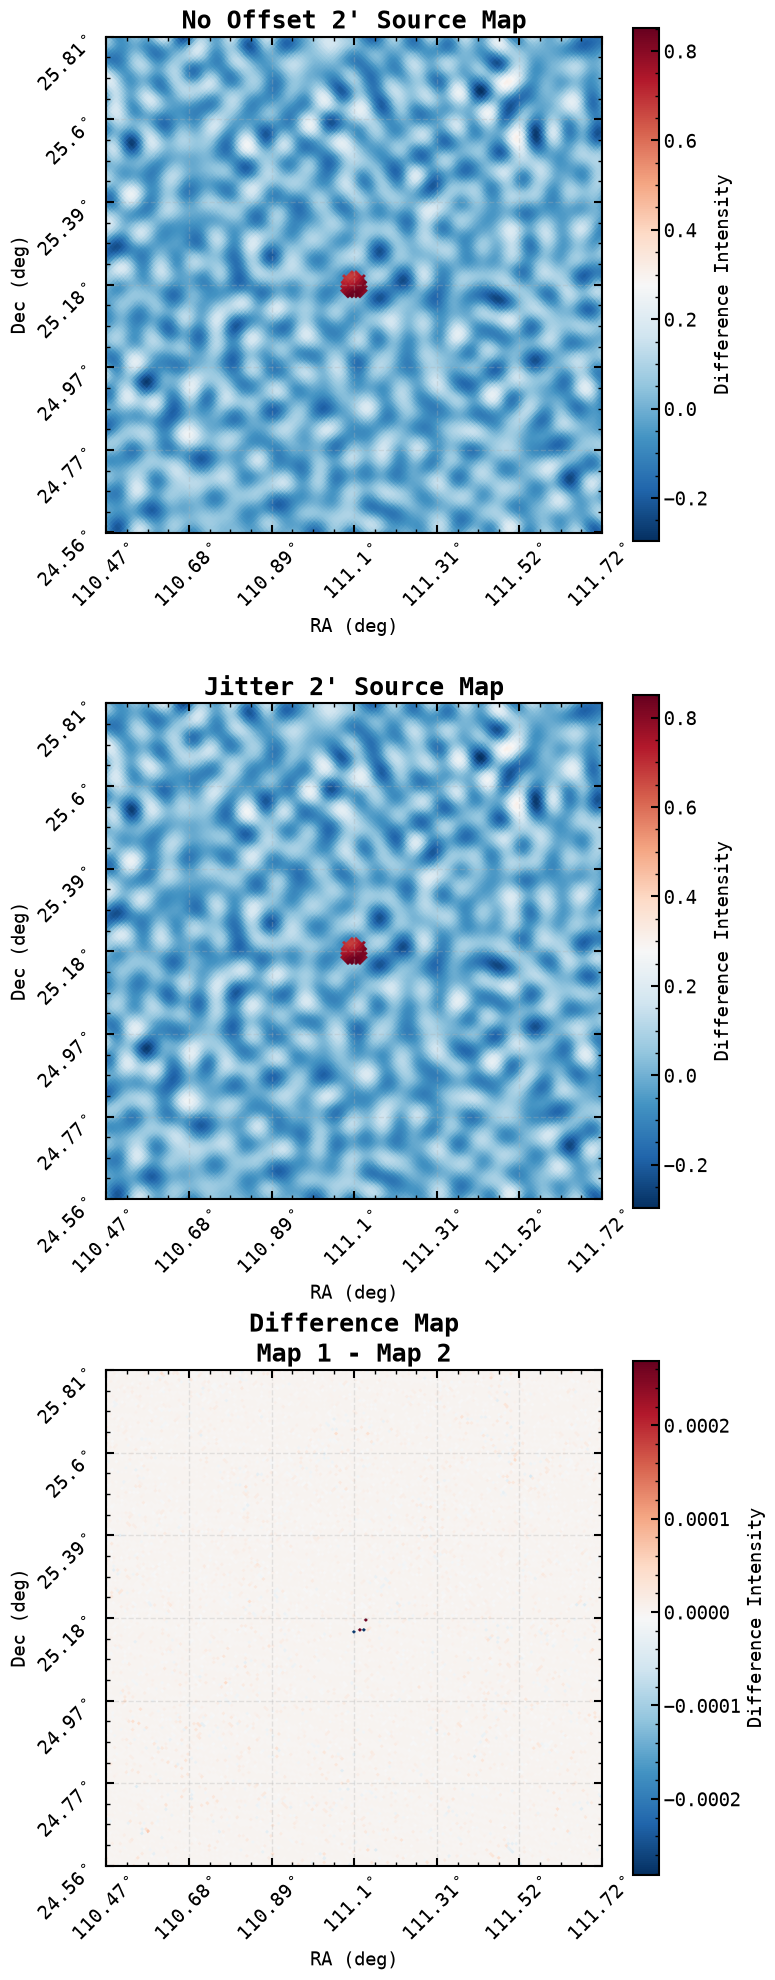

In [20]:
fig, axs = diff_plot(maps_dict["plain"]["map"],
          maps_dict["jitter"]["map"],
          rot=rot,
          xsize=750,
          reso=0.1,
          show=False)

axs[0].set_title("No Offset 2' Source Map")
axs[1].set_title("Jitter 2' Source Map")
plt.savefig(os.path.join(fig_out_path, "2arcmin_jitter_diff.png"))